In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
df=pd.read_csv('/content/amazon_prime_titles.csv')
df


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,"March 30, 2021",2014,NaN,113 min,"Comedy, Drama",A small fishing village must procure a local d...
1,s2,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,"March 30, 2021",2018,13+,110 min,"Drama, International",A Metro Family decides to fight a Cyber Crimin...
2,s3,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,"March 30, 2021",2017,NaN,74 min,"Action, Drama, Suspense",After a man discovers his wife is cheating on ...
3,s4,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, BeyoncÃ©, Britne...",United States,"March 30, 2021",2014,NaN,69 min,Documentary,"Pink breaks the mold once again, bringing her ..."
4,s5,Movie,Monster Maker,Giles Foster,"Harry Dean Stanton, Kieran O'Brien, George Cos...",United Kingdom,"March 30, 2021",1989,NaN,45 min,"Drama, Fantasy",Teenage Matt Banting wants to work with a famo...
...,...,...,...,...,...,...,...,...,...,...,...,...
9663,s9664,Movie,Pride Of The Bowery,Joseph H. Lewis,"Leo Gorcey, Bobby Jordan",NaN,NaN,1940,7+,60 min,Comedy,New York City street principles get an East Si...
9664,s9665,TV Show,Planet Patrol,NaN,"DICK VOSBURGH, RONNIE STEVENS, LIBBY MORRIS, M...",NaN,NaN,2018,13+,4 Seasons,TV Shows,"This is Earth, 2100AD - and these are the adve..."
9665,s9666,Movie,Outpost,Steve Barker,"Ray Stevenson, Julian Wadham, Richard Brake, M...",NaN,NaN,2008,R,90 min,Action,"In war-torn Eastern Europe, a world-weary grou..."
9666,s9667,TV Show,Maradona: Blessed Dream,NaN,"Esteban Recagno, Ezequiel Stremiz, Luciano Vit...",NaN,NaN,2021,TV-MA,1 Season,"Drama, Sports","The series tells the story of Diego Maradona, ..."


In [50]:
df.shape

(9668, 12)

In [51]:
df.size

116016

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9668 entries, 0 to 9667
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       9668 non-null   object
 1   type          9668 non-null   object
 2   title         9668 non-null   object
 3   director      7585 non-null   object
 4   cast          8435 non-null   object
 5   country       672 non-null    object
 6   date_added    155 non-null    object
 7   release_year  9668 non-null   int64 
 8   rating        9331 non-null   object
 9   duration      9668 non-null   object
 10  listed_in     9668 non-null   object
 11  description   9668 non-null   object
dtypes: int64(1), object(11)
memory usage: 906.5+ KB


In [53]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [54]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2083
cast,1233
country,8996
date_added,9513
release_year,0
rating,337
duration,0


In [55]:
missing_values= df.isnull().sum()
total_rows=len(df)
missing_percentage= (missing_values/total_rows)*100
print(missing_percentage)

show_id          0.000000
type             0.000000
title            0.000000
director        21.545304
cast            12.753413
country         93.049235
date_added      98.396773
release_year     0.000000
rating           3.485726
duration         0.000000
listed_in        0.000000
description      0.000000
dtype: float64


In [56]:
df.duplicated().sum()

np.int64(0)

In [57]:
#to check the content category
df['type'].value_counts()

,count
type,
Movie,7814
TV Show,1854


In [58]:
df.clean=df.copy()

/tmp/ipykernel_2768/3337392917.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.clean=df.copy()


In [59]:
df['date_added'].head(10)

,date_added
0,"March 30, 2021"
1,"March 30, 2021"
2,"March 30, 2021"
3,"March 30, 2021"
4,"March 30, 2021"
5,"March 30, 2021"
6,"March 30, 2021"
7,"March 30, 2021"
8,"March 30, 2021"
9,"April 1, 2021"


In [60]:
df['date_added'].dtype

dtype('O')

In [61]:
df['date_added'].iloc[101:118]

,date_added
101,NaN
102,NaN
103,NaN
104,NaN
105,NaN
106,NaN
107,NaN
108,NaN
109,NaN
110,NaN


In [62]:
df['date_added'].tail(10)

,date_added
9658,NaN
9659,NaN
9660,NaN
9661,NaN
9662,NaN
9663,NaN
9664,NaN
9665,NaN
9666,NaN
9667,NaN


In [63]:
print('total_rows:', len(df))
print('Dates_available:', df['date_added'].count())
print(df['date_added'].isnull().sum())
df[df['date_added'].notnull()].head(10)

#df["date_added"] selects the date column.
#notnull() checks which rows have a date.
#df[...] displays only the rows that satisfy the condition.
#head(10) displays the first 10 matching rows.

total_rows: 9668
Dates_available: 155
9513


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,The Grand Seduction,Don McKellar,"Brendan Gleeson, Taylor Kitsch, Gordon Pinsent",Canada,"March 30, 2021",2014,NaN,113 min,"Comedy, Drama",A small fishing village must procure a local d...
1,s2,Movie,Take Care Good Night,Girish Joshi,"Mahesh Manjrekar, Abhay Mahajan, Sachin Khedekar",India,"March 30, 2021",2018,13+,110 min,"Drama, International",A Metro Family decides to fight a Cyber Crimin...
2,s3,Movie,Secrets of Deception,Josh Webber,"Tom Sizemore, Lorenzo Lamas, Robert LaSardo, R...",United States,"March 30, 2021",2017,NaN,74 min,"Action, Drama, Suspense",After a man discovers his wife is cheating on ...
3,s4,Movie,Pink: Staying True,Sonia Anderson,"Interviews with: Pink, Adele, BeyoncÃ©, Britne...",United States,"March 30, 2021",2014,NaN,69 min,Documentary,"Pink breaks the mold once again, bringing her ..."
4,s5,Movie,Monster Maker,Giles Foster,"Harry Dean Stanton, Kieran O'Brien, George Cos...",United Kingdom,"March 30, 2021",1989,NaN,45 min,"Drama, Fantasy",Teenage Matt Banting wants to work with a famo...
5,s6,Movie,Living With Dinosaurs,Paul Weiland,"Gregory Chisholm, Juliet Stevenson, Brian Hens...",United Kingdom,"March 30, 2021",1989,NaN,52 min,"Fantasy, Kids",The story unfolds in a an English seaside town...
6,s7,Movie,Hired Gun,Fran Strine,"Alice Cooper, Liberty DeVitto, Ray Parker Jr.,...",United States,"March 30, 2021",2017,NaN,98 min,"Documentary, Special Interest","They are the ""First Call, A-list"" musicians, j..."
7,s8,Movie,Grease Live!,"Thomas Kail, Alex Rudzinski","Julianne Hough, Aaron Tveit, Vanessa Hudgens, ...",United States,"March 30, 2021",2016,NaN,131 min,Comedy,"This honest, uncompromising comedy chronicles ..."
8,s9,Movie,Global Meltdown,Daniel Gilboy,"Michael ParÃ©, Leanne Khol Young, Patrick J. M...",Canada,"March 30, 2021",2017,NaN,87 min,"Action, Science Fiction, Suspense",A helicopter pilot and an environmental scient...
9,s10,Movie,David's Mother,Robert Allan Ackerman,"Kirstie Alley, Sam Waterston, Stockard Channing",United States,"April 1, 2021",1994,NaN,92 min,Drama,Sally Goodson is a devoted mother to her autis...


In [64]:
#to find the first and last rows with dates
print("First row with a date:")
print(df["date_added"].first_valid_index())

print("Last row with a date:")
print(df["date_added"].last_valid_index())

#this says that the dates exists near both the begining and the end of the dateset so the missing values are not simply located at the end

First row with a date:
0
Last row with a date:
9647


In [65]:
df[df['date_added'].notnull()].shape
#This shows how many rows contain a date and how many columns those rows have.

(155, 12)

In [66]:
df[146:165][['title','date_added']]
#this displays title and date from 146 to 164

,title,date_added
146,Watermelon Man,NaN
147,Waterfalls for Sleep 8 Hours,NaN
148,WATER (short),NaN
149,Watch the Game Like Never Before with X-Ray,NaN
150,Wash Your Hands & More Classic Kids Songs - Ki...,NaN
151,War of Likes,NaN
152,War Comes to America,NaN
153,War (Telugu),NaN
154,War (Tamil),NaN
155,Walter Williams: Suffer No Fools,NaN


In [67]:
#count missing dates in groups of 1000 rows
for start in range(0, len(df), 1000):
    end = start + 1000
    section = df[start:end]
    print("Rows", start, "to", min(end, len(df)) - 1)
    print("Dates available:", section["date_added"].count())
    print()

Rows 0 to 999
Dates available: 17

Rows 1000 to 1999
Dates available: 2

Rows 2000 to 2999
Dates available: 2

Rows 3000 to 3999
Dates available: 2

Rows 4000 to 4999
Dates available: 10

Rows 5000 to 5999
Dates available: 24

Rows 6000 to 6999
Dates available: 27

Rows 7000 to 7999
Dates available: 23

Rows 8000 to 8999
Dates available: 28

Rows 9000 to 9667
Dates available: 20



In [68]:
#Display the first 20 records without shortening the table
print(df[["show_id", "title", "date_added"]].head(20).to_string(index=False))

print(df[["show_id", "title", "date_added"]].sample(15, random_state=42).to_string(index=False))


show_id                             title     date_added
     s1               The Grand Seduction March 30, 2021
     s2              Take Care Good Night March 30, 2021
     s3              Secrets of Deception March 30, 2021
     s4                Pink: Staying True March 30, 2021
     s5                     Monster Maker March 30, 2021
     s6             Living With Dinosaurs March 30, 2021
     s7                         Hired Gun March 30, 2021
     s8                      Grease Live! March 30, 2021
     s9                   Global Meltdown March 30, 2021
    s10                    David's Mother  April 1, 2021
    s11                    Forest Fairies  April 4, 2021
    s12                         Take Care April 10, 2021
    s13          The Night Eats The World April 17, 2021
    s14                        Resilencia April 24, 2021
    s15 Elon Musk: The Real Life Iron Man    May 2, 2021
    s16                        Summer '03   June 3, 2021
    s17                        

In [69]:
#to check weather the dataset is loaded  correctly
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())


Number of rows: 9668
Number of columns: 12
Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [72]:
df_clean = df.copy()
df_clean[["director", "cast", "country", "rating"]].isnull().sum()

,0
director,2083
cast,1233
country,8996
rating,337


In [79]:
df_clean[["director", "cast", "country", "rating"]] = df_clean[["director", "cast", "country", "rating"]].fillna('unknown')
df_clean.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,9513
release_year,0
rating,0
duration,0


In [80]:
df_clean["duration"].head(10)


,duration
0,113 min
1,110 min
2,74 min
3,69 min
4,45 min
5,52 min
6,98 min
7,131 min
8,87 min
9,92 min


In [81]:

print(df_clean["type"].value_counts())

type
Movie      7814
TV Show    1854
Name: count, dtype: int64


In [88]:
df_clean["duration_number"] = df_clean["duration"].str.extract(r"(\d+)")

df_clean["duration_number"] = pd.to_numeric(
    df_clean["duration_number"],
    errors="coerce"
)
df_clean["movie_duration"] = df_clean["duration_number"].where(
    df_clean["type"] == "Movie"
)

df_clean["tv_seasons"] = df_clean["duration_number"].where(
    df_clean["type"] == "TV Show"
)

In [86]:
df_clean[["type", "duration", "movie_duration", "tv_seasons"]].head(10)

,type,duration,movie_duration,tv_seasons
0,Movie,113 min,113.0,NaN
1,Movie,110 min,110.0,NaN
2,Movie,74 min,74.0,NaN
3,Movie,69 min,69.0,NaN
4,Movie,45 min,45.0,NaN
5,Movie,52 min,52.0,NaN
6,Movie,98 min,98.0,NaN
7,Movie,131 min,131.0,NaN
8,Movie,87 min,87.0,NaN
9,Movie,92 min,92.0,NaN


In [87]:

print("Movie durations available:", df_clean["movie_duration"].count())
print("TV-show seasons available:", df_clean["tv_seasons"].count())

Movie durations available: 7814
TV-show seasons available: 1854


In [89]:
# Check the dataset size
print("Dataset shape:", df_clean.shape)

# Check missing values
print("\nMissing values:")
print(df_clean.isnull().sum())

# Check the content types
print("\nContent types:")
print(df_clean["type"].value_counts())

Dataset shape: (9668, 15)

Missing values:
show_id               0
type                  0
title                 0
director              0
cast                  0
country               0
date_added         9513
release_year          0
rating                0
duration              0
listed_in             0
description           0
duration_number       0
movie_duration     1854
tv_seasons         7814
dtype: int64

Content types:
type
Movie      7814
TV Show    1854
Name: count, dtype: int64


In [90]:
#Does Amazon Prime's catalogue contain more movies or TV shows?
content_counts = df_clean["type"].value_counts()

content_percentages = (
    df_clean["type"].value_counts(normalize=True) * 100
)

print("Number of titles by type:")
print(content_counts)

print("\nPercentage of catalogue by type:")
print(content_percentages.round(2))

Number of titles by type:
type
Movie      7814
TV Show    1854
Name: count, dtype: int64

Percentage of catalogue by type:
type
Movie      80.82
TV Show    19.18
Name: proportion, dtype: float64


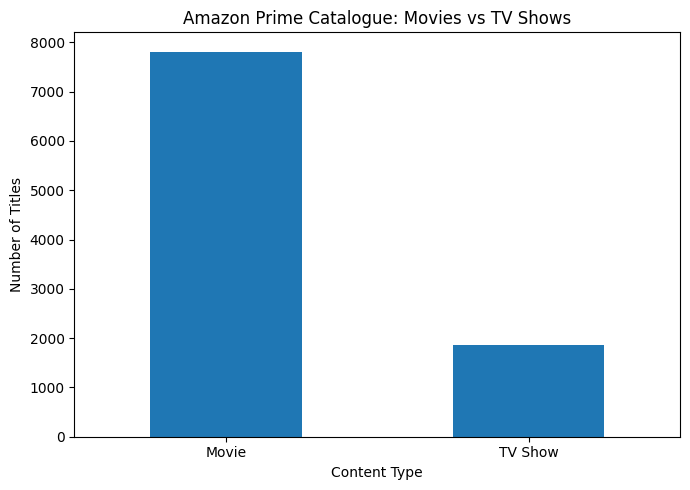

In [92]:

import matplotlib.pyplot as plt

content_counts = df_clean["type"].value_counts()

content_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Amazon Prime Catalogue: Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [93]:
print("Earliest release year:", df_clean["release_year"].min())
print("Latest release year:", df_clean["release_year"].max())

print("\nMost common release years:")
print(df_clean["release_year"].value_counts().head(10))

Earliest release year: 1920
Latest release year: 2021

Most common release years:
release_year
2021    1442
2020     962
2019     929
2018     623
2017     562
2016     521
2014     391
2015     378
2013     289
2012     252
Name: count, dtype: int64


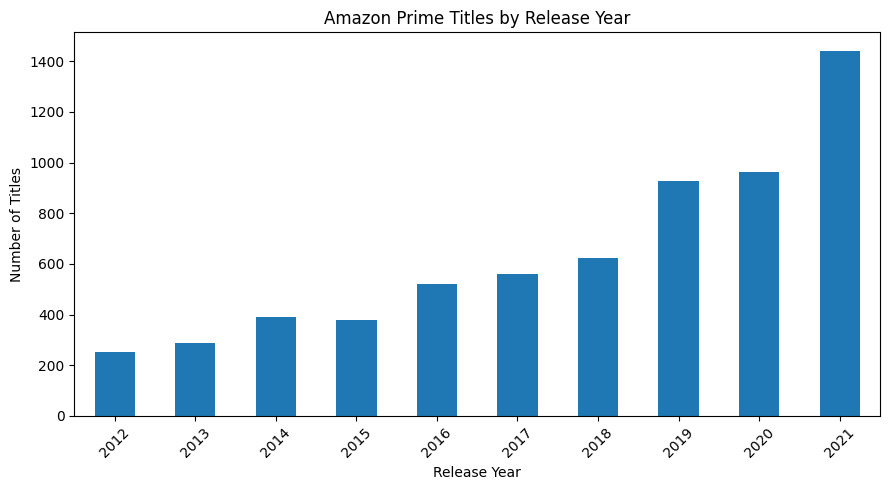

In [94]:

import matplotlib.pyplot as plt

top_years = df_clean["release_year"].value_counts().head(10)
top_years = top_years.sort_index()

top_years.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Amazon Prime Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [95]:
year_counts = df_clean["release_year"].value_counts()

for year in [2018, 2019, 2020, 2021]:
    print(f"{year}: {year_counts.get(year, 0)} titles")

increase = year_counts.get(2021, 0) - year_counts.get(2020, 0)
percentage_increase = increase / year_counts.get(2020, 0) * 100

print(f"\nIncrease from 2020 to 2021: {increase} titles")
print(f"Percentage increase: {percentage_increase:.2f}%")

2018: 623 titles
2019: 929 titles
2020: 962 titles
2021: 1442 titles

Increase from 2020 to 2021: 480 titles
Percentage increase: 49.90%


In [96]:
df_clean["listed_in"].head(10)

,listed_in
0,"Comedy, Drama"
1,"Drama, International"
2,"Action, Drama, Suspense"
3,Documentary
4,"Drama, Fantasy"
5,"Fantasy, Kids"
6,"Documentary, Special Interest"
7,Comedy
8,"Action, Science Fiction, Suspense"
9,Drama


In [97]:
genres = df_clean["listed_in"].str.split(", ").explode()

print("Total genre assignments:", len(genres))
print("\nTop 10 genres:")
print(genres.value_counts().head(10))

Total genre assignments: 18309

Top 10 genres:
listed_in
Drama               3687
Comedy              2099
Action              1657
Suspense            1501
Kids                1085
Documentary          993
Special Interest     980
Horror               875
Romance              674
Animation            547
Name: count, dtype: int64


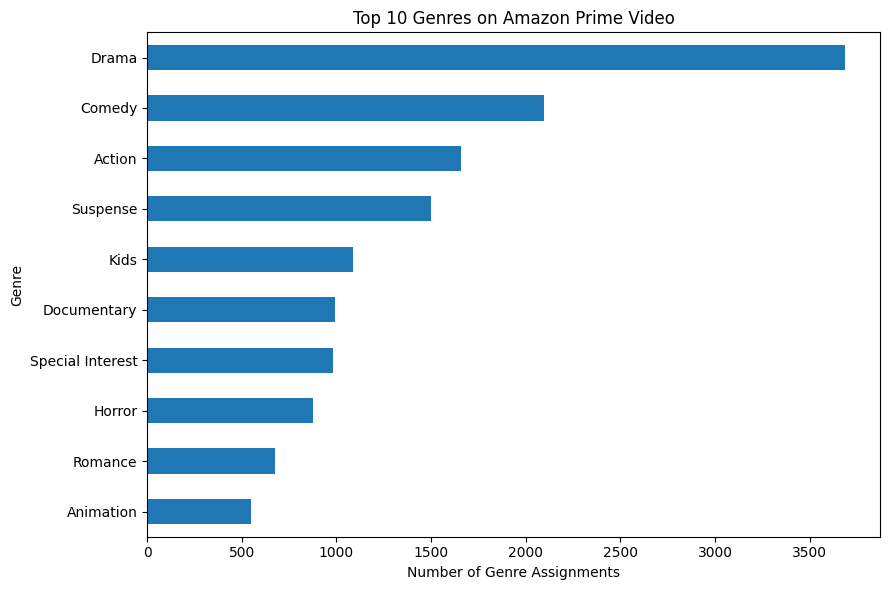

In [98]:

import matplotlib.pyplot as plt

genres = df_clean["listed_in"].str.split(", ").explode()
top_genres = genres.value_counts().head(10).sort_values()

top_genres.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 10 Genres on Amazon Prime Video")
plt.xlabel("Number of Genre Assignments")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


Genre distribution

Drama is the most frequently assigned genre in the Amazon Prime Video dataset, with 3,687 assignments, followed by Comedy (2,099) and Action (1,657). These results describe the composition of the available catalogue; they do not indicate customer viewing preferences or genre profitability.

In [99]:
df_clean["country"].head(15)

,country
0,Canada
1,India
2,United States
3,United States
4,United Kingdom
5,United Kingdom
6,United States
7,United States
8,Canada
9,United States


In [100]:
countries = (
    df_clean.loc[df_clean["country"] != "Unknown", "country"]
    .str.split(", ")
    .explode()
    .str.strip()
)

print("Number of country assignments:", len(countries))
print("\nTop 10 countries:")
print(countries.value_counts().head(10))

Number of country assignments: 9820

Top 10 countries:
country
unknown           8996
United States      334
India              246
United Kingdom      67
Canada              35
France              20
Germany             17
Italy               14
Spain               11
Japan                6
Name: count, dtype: int64


In [101]:

countries = (
    df_clean.loc[
        ~df_clean["country"].str.strip().str.lower().isin(
            ["unknown", ""]
        ),
        "country"
    ]
    .str.split(", ")
    .explode()
    .str.strip()
)

print("Number of country assignments:", len(countries))
print("\nTop 10 countries:")
print(countries.value_counts().head(10))


Number of country assignments: 824

Top 10 countries:
country
United States     334
India             246
United Kingdom     67
Canada             35
France             20
Germany            17
Italy              14
Spain              11
Japan               6
China               6
Name: count, dtype: int64


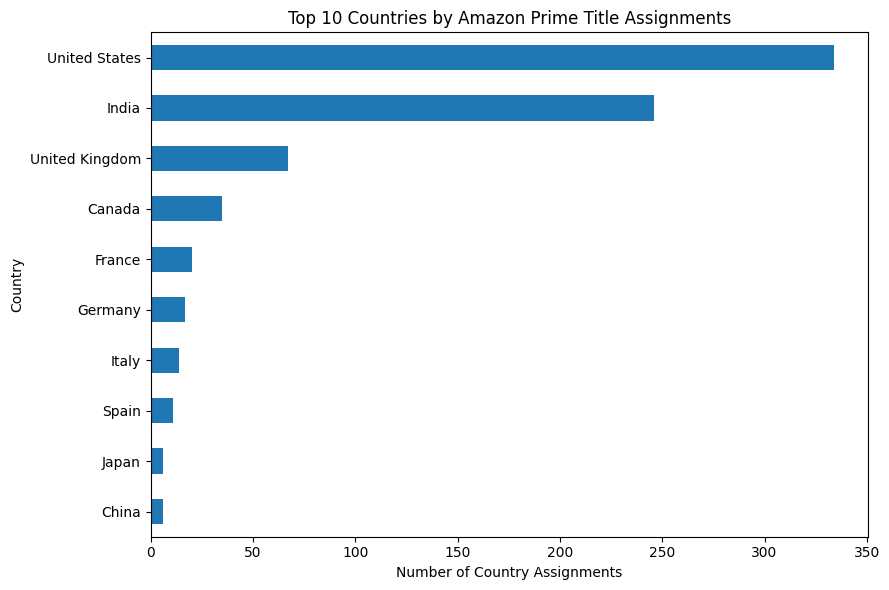

In [102]:

import matplotlib.pyplot as plt

top_countries = countries.value_counts().head(10).sort_values()

top_countries.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 10 Countries by Amazon Prime Title Assignments")
plt.xlabel("Number of Country Assignments")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


In [103]:
#rating content
print(df_clean["rating"].value_counts().head(15))

rating
13+        2117
16+        1547
ALL        1268
18+        1243
R          1010
PG-13       393
7+          385
unknown     337
PG          253
NR          223
TV-14       208
TV-PG       169
TV-NR       105
G            93
TV-G         81
Name: count, dtype: int64


In [104]:
rating_counts = df_clean["rating"].value_counts()

print("Number of distinct rating labels:", df_clean["rating"].nunique())
print("\nAll rating labels:")
print(rating_counts.to_string())


Number of distinct rating labels: 25

All rating labels:
rating
13+         2117
16+         1547
ALL         1268
18+         1243
R           1010
PG-13        393
7+           385
unknown      337
PG           253
NR           223
TV-14        208
TV-PG        169
TV-NR        105
G             93
TV-G          81
TV-MA         77
TV-Y          74
TV-Y7         39
UNRATED       33
NC-17          3
AGES_18_       3
NOT_RATE       3
AGES_16_       2
16             1
ALL_AGES       1


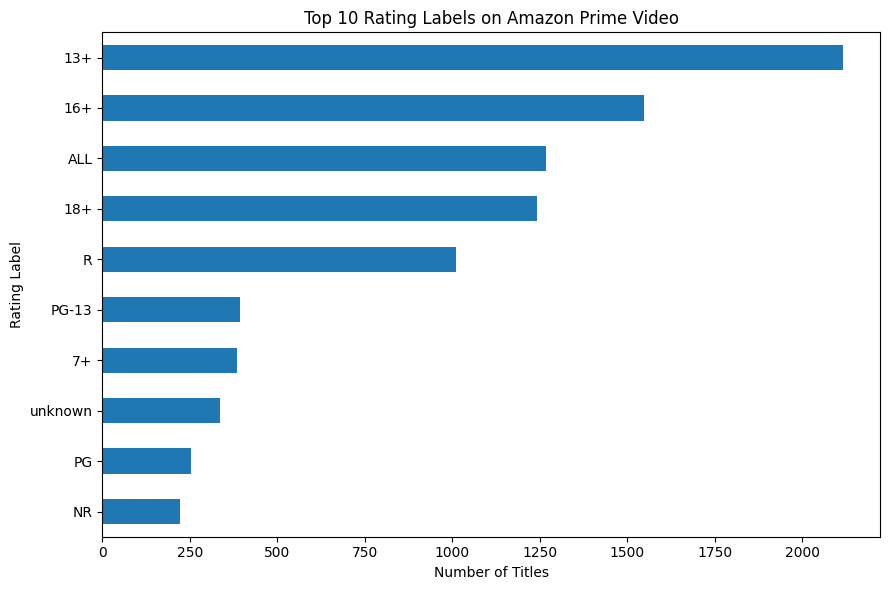

In [105]:

import matplotlib.pyplot as plt

top_ratings = df_clean["rating"].value_counts().head(10).sort_values()

top_ratings.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 10 Rating Labels on Amazon Prime Video")
plt.xlabel("Number of Titles")
plt.ylabel("Rating Label")
plt.tight_layout()
plt.show()


In [106]:

# 1. Check duplicate title names
print(
    "Duplicate title names:",
    df_clean["title"].duplicated().sum()
)

# 2. Check release-year range
print(
    "Earliest release year:",
    df_clean["release_year"].min()
)
print(
    "Latest release year:",
    df_clean["release_year"].max()
)

# 3. Check content types
print("\nContent type counts:")
print(df_clean["type"].value_counts())

# 4. Check remaining missing values
print("\nMissing values by column:")
print(df_clean.isnull().sum())


Duplicate title names: 0
Earliest release year: 1920
Latest release year: 2021

Content type counts:
type
Movie      7814
TV Show    1854
Name: count, dtype: int64

Missing values by column:
show_id               0
type                  0
title                 0
director              0
cast                  0
country               0
date_added         9513
release_year          0
rating                0
duration              0
listed_in             0
description           0
duration_number       0
movie_duration     1854
tv_seasons         7814
dtype: int64


# Amazon Prime Video — Exploratory Data Analysis

## Project objective

Explore the Amazon Prime Video catalogue to understand its content composition, release-year distribution, genre distribution, country representation, and rating labels.

## Key findings

1. **Content type:** Movies account for 80.82% of the 9,668 titles, while TV shows account for 19.18%.

2. **Release years:** 2021 is the most represented release year in this dataset, with 1,442 titles. The dataset's release years range from 1920 to 2021.

3. **Genres:** Drama is the most frequently assigned genre, followed by Comedy and Action.

4. **Country representation:** Among recorded country assignments, the United States ranks first, followed by India and the United Kingdom.

5. **Ratings:** `13+` is the most frequent individual rating label. The dataset contains multiple rating systems, so the labels should not be combined without a clearly defined mapping.

## Data-quality limitations

- The `date_added` column is missing for 9,513 titles, limiting analysis of when titles were added to the platform.
- Country information is missing for most records, so country findings represent only records with recorded country information.
- A title can have multiple genres and countries, meaning those counts are assignments rather than mutually exclusive title counts.
- The latest release year in the dataset is 2021; the findings should not be presented as a description of the current catalogue without newer data.

## Conclusion

The dataset is heavily weighted toward movies, with Drama the most frequently assigned genre and the United States the most frequently listed country among records with country information. These findings describe the catalogue's recorded characteristics, not customer viewing preferences, platform growth, or revenue.